# 03 — Comparação de modelos (XGBoost vs LDA vs Reg. Logística vs KNN)

**Tarefa:** classificação multiclasse `Healthy / COPD / URTI` sobre as 78 features extraídas no notebook 02.

**Pontos críticos:**
- Split **paciente-estratificado** (`StratifiedGroupKFold` com `groups=patient_id`) — gravações de um mesmo paciente nunca aparecem em treino e teste juntas.
- Avaliação em **dois níveis**: gravação (out-of-fold) e paciente (voto majoritário).
- Matriz de confusão **com contagem de pacientes**.
- `StandardScaler` em pipeline para LDA, LogReg e KNN (XGBoost não precisa).

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

from src import config

sns.set_theme(style='whitegrid')

## 1. Carregar features

In [2]:
feats_df = pd.read_csv(config.PROCESSED_DIR / 'features.csv')
print(f'Shape: {feats_df.shape}')
print(feats_df['label_multi'].value_counts())
feats_df.head()

Shape: (851, 84)
label_multi
COPD       793
Healthy     35
URTI        23
Name: count, dtype: int64


,mfcc1_mean,mfcc1_std,mfcc1_d_mean,mfcc1_d2_mean,mfcc2_mean,mfcc2_std,mfcc2_d_mean,mfcc2_d2_mean,mfcc3_mean,mfcc3_std,...,rolloff_mean,bandwidth_mean,flatness_mean,duration_s,filename,patient_id,equipment,chest_location,label_multi,label_binary
0,-528.425232,28.375187,-0.017549,0.236458,104.517365,24.670374,0.004808,0.036089,69.907585,15.964994,...,102.857267,647.469627,6.019614e-06,20.000000,101_1b1_Al_sc_Meditron.wav,101,WelchAllyn Meditron,Anterior left,URTI,Disease
1,-582.504700,24.621038,0.072162,0.178364,95.394691,22.027939,0.062635,0.011000,57.402180,11.650138,...,81.761223,816.768435,9.156409e-06,20.000000,101_1b1_Pr_sc_Meditron.wav,101,WelchAllyn Meditron,Posterior right,URTI,Disease
2,-596.806091,22.520979,-0.017105,0.115947,116.009735,24.727230,-0.043550,0.042133,60.592537,16.616146,...,138.804226,870.775844,1.028045e-05,20.000000,102_1b1_Ar_sc_Meditron.wav,102,WelchAllyn Meditron,Anterior right,Healthy,Healthy
3,-441.498169,40.611320,-0.063146,0.015621,100.994278,47.306488,-0.088244,0.009985,74.064339,24.414709,...,221.921254,152.844687,2.126648e-08,15.856009,104_1b1_Al_sc_Litt3200.wav,104,Littmann 3200 Electronic,Anterior left,COPD,Disease
4,-443.037079,40.578865,0.003159,0.016769,106.827316,45.878059,0.013043,0.021375,74.783844,21.028540,...,287.220102,181.379660,9.291450e-09,25.584036,104_1b1_Ar_sc_Litt3200.wav,104,Littmann 3200 Electronic,Anterior right,COPD,Disease


## 2. Preparar X, y, groups

`y` codificado numericamente (XGBoost exige). `groups` = `patient_id` para o split.

In [3]:
FEATURE_COLS = [c for c in feats_df.columns
                if c not in ('filename', 'patient_id', 'equipment',
                             'chest_location', 'label_multi', 'label_binary')]
print(f'# features: {len(FEATURE_COLS)}')

X = feats_df[FEATURE_COLS].values
le = LabelEncoder()
y = le.fit_transform(feats_df['label_multi'])
groups = feats_df['patient_id'].values
CLASSES = list(le.classes_)
print('Classes:', CLASSES)

# features: 78
Classes: ['COPD', 'Healthy', 'URTI']


## 3. Definir modelos

Todos em `Pipeline` com `StandardScaler` (exceto XGBoost que é invariante à escala — mas mantemos para consistência).

In [4]:
models = {
    'XGBoost': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', XGBClassifier(
            n_estimators=300, max_depth=5, learning_rate=0.1,
            eval_metric='mlogloss', random_state=42, n_jobs=1)),
    ]),
    'LDA': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LinearDiscriminantAnalysis()),
    ]),
    'LogReg': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=2000, class_weight='balanced',
                                   random_state=42)),
    ]),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=5, weights='distance')),
    ]),
}
list(models.keys())

['XGBoost', 'LDA', 'LogReg', 'KNN']

## 4. Cross-validation paciente-estratificado (5 folds)

Geramos predições **out-of-fold** para cada gravação — cada gravação é predita uma única vez por um modelo que **nunca viu seu paciente** no treino.

In [5]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

results = {}
for name, model in models.items():
    print(f'>>> {name}')
    y_pred = cross_val_predict(model, X, y, groups=groups, cv=cv, n_jobs=-1)
    results[name] = {
        'y_pred': y_pred,
        'acc': accuracy_score(y, y_pred),
        'f1_macro': f1_score(y, y_pred, average='macro'),
        'f1_weighted': f1_score(y, y_pred, average='weighted'),
    }
print('Concluído.')

>>> XGBoost


>>> LDA


>>> LogReg


>>> KNN


Concluído.


## 5. Comparativo de métricas (nível de gravação)

         Accuracy  F1-macro  F1-weighted
KNN         0.949     0.608        0.950
LogReg      0.931     0.545        0.938
LDA         0.928     0.544        0.938
XGBoost     0.942     0.524        0.941


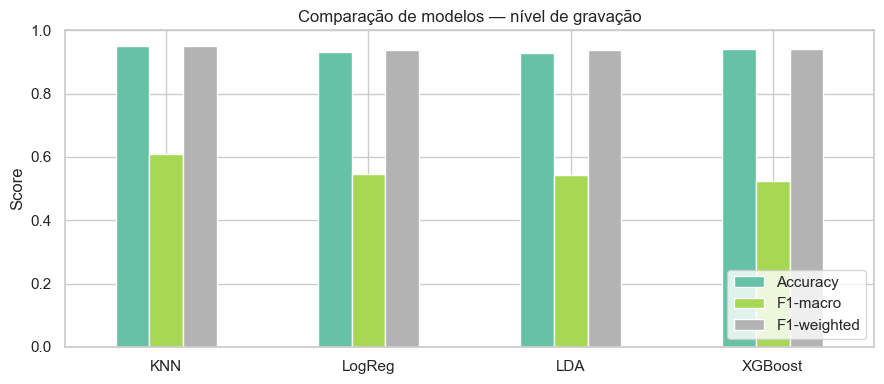

In [6]:
metrics_df = pd.DataFrame({
    'Accuracy': {k: v['acc'] for k, v in results.items()},
    'F1-macro': {k: v['f1_macro'] for k, v in results.items()},
    'F1-weighted': {k: v['f1_weighted'] for k, v in results.items()},
}).round(3)
metrics_df = metrics_df.sort_values('F1-macro', ascending=False)
print(metrics_df)

fig, ax = plt.subplots(figsize=(9, 4))
metrics_df.plot(kind='bar', ax=ax, colormap='Set2')
ax.set_title('Comparação de modelos — nível de gravação')
ax.set_ylabel('Score'); ax.set_xlabel('')
ax.set_ylim(0, 1); ax.tick_params(axis='x', rotation=0)
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

## 6. Classification report detalhado

In [7]:
for name, r in results.items():
    print(f'\n===== {name} =====')
    print(classification_report(y, r['y_pred'], target_names=CLASSES, digits=3))


===== XGBoost =====
              precision    recall  f1-score   support

        COPD      0.985     0.989     0.987       793
     Healthy      0.389     0.400     0.394        35
        URTI      0.211     0.174     0.190        23

    accuracy                          0.942       851
   macro avg      0.528     0.521     0.524       851
weighted avg      0.939     0.942     0.941       851


===== LDA =====
              precision    recall  f1-score   support

        COPD      0.996     0.967     0.981       793
     Healthy      0.375     0.429     0.400        35
        URTI      0.195     0.348     0.250        23

    accuracy                          0.928       851
   macro avg      0.522     0.581     0.544       851
weighted avg      0.949     0.928     0.938       851


===== LogReg =====
              precision    recall  f1-score   support

        COPD      0.995     0.968     0.981       793
     Healthy      0.353     0.514     0.419        35
        URTI     

## 7. Agregação para nível de paciente (voto majoritário)

Cada paciente tem várias gravações. Agregamos por voto majoritário das predições out-of-fold para obter **um único diagnóstico por paciente** — visão clinicamente realista do desempenho.

In [8]:
def aggregate_to_patient(y_pred, feats_df, classes):
    pred_labels = np.array([classes[i] for i in y_pred])
    tmp = feats_df[['patient_id', 'label_multi']].copy()
    tmp['pred'] = pred_labels
    agg = tmp.groupby('patient_id').agg(
        y_true=('label_multi', 'first'),
        y_pred=('pred', lambda s: s.value_counts().idxmax()),
    ).reset_index()
    return agg

patient_results = {}
for name, r in results.items():
    agg = aggregate_to_patient(r['y_pred'], feats_df, CLASSES)
    patient_results[name] = agg
    acc = (agg['y_true'] == agg['y_pred']).mean()
    f1m = f1_score(agg['y_true'], agg['y_pred'], average='macro')
    print(f'{name:8s}  pacientes={len(agg)}  acc={acc:.3f}  F1-macro={f1m:.3f}')

XGBoost   pacientes=104  acc=0.721  F1-macro=0.513
LDA       pacientes=104  acc=0.721  F1-macro=0.547
LogReg    pacientes=104  acc=0.731  F1-macro=0.583
KNN       pacientes=104  acc=0.760  F1-macro=0.612


## 8. Matriz de confusão (pacientes)

Os números nas células são **contagens de pacientes** — exatamente o que importa clinicamente.

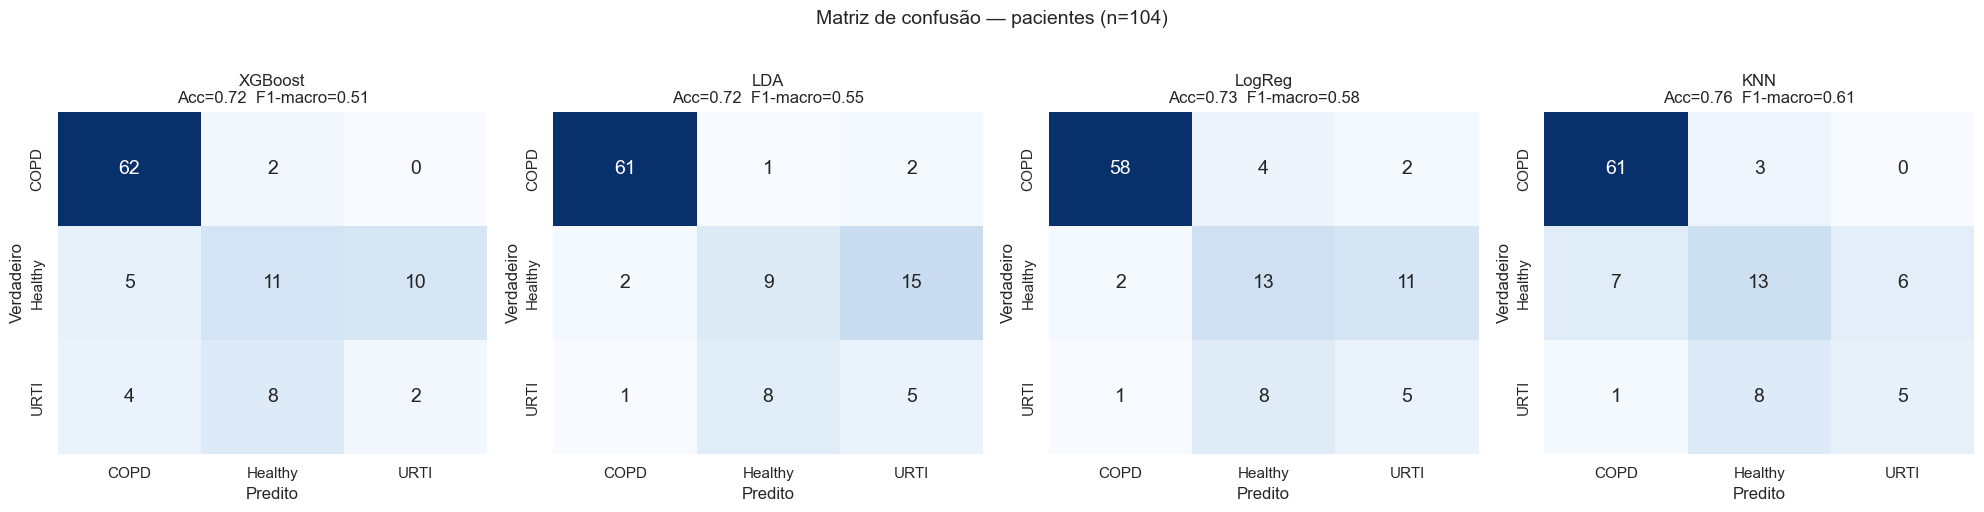

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (name, agg) in zip(axes, patient_results.items()):
    cm = confusion_matrix(agg['y_true'], agg['y_pred'], labels=CLASSES)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASSES, yticklabels=CLASSES,
                cbar=False, ax=ax, annot_kws={'size': 14})
    acc = (agg['y_true'] == agg['y_pred']).mean()
    f1m = f1_score(agg['y_true'], agg['y_pred'], average='macro')
    ax.set_title(f'{name}\nAcc={acc:.2f}  F1-macro={f1m:.2f}', fontsize=12)
    ax.set_xlabel('Predito'); ax.set_ylabel('Verdadeiro')
plt.suptitle('Matriz de confusão — pacientes (n=104)', fontsize=14, y=1.02)
plt.tight_layout(); plt.show()

### Matriz de confusão também a nível de gravação (referência)

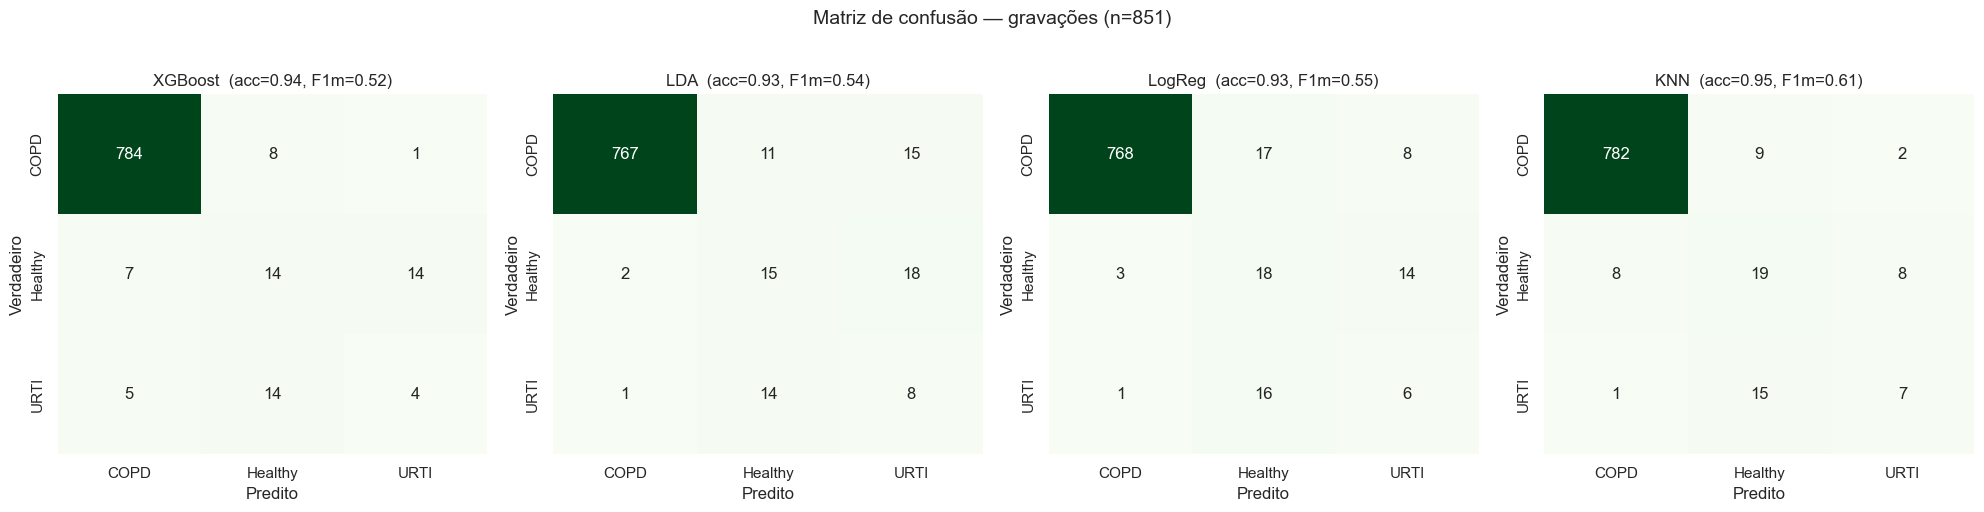

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(y, r['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
                xticklabels=CLASSES, yticklabels=CLASSES,
                cbar=False, ax=ax, annot_kws={'size': 12})
    ax.set_title(f"{name}  (acc={r['acc']:.2f}, F1m={r['f1_macro']:.2f})")
    ax.set_xlabel('Predito'); ax.set_ylabel('Verdadeiro')
plt.suptitle('Matriz de confusão — gravações (n=851)', fontsize=14, y=1.02)
plt.tight_layout(); plt.show()

## 9. Feature importance (XGBoost)

Quais features carregam mais sinal para distinguir as classes?

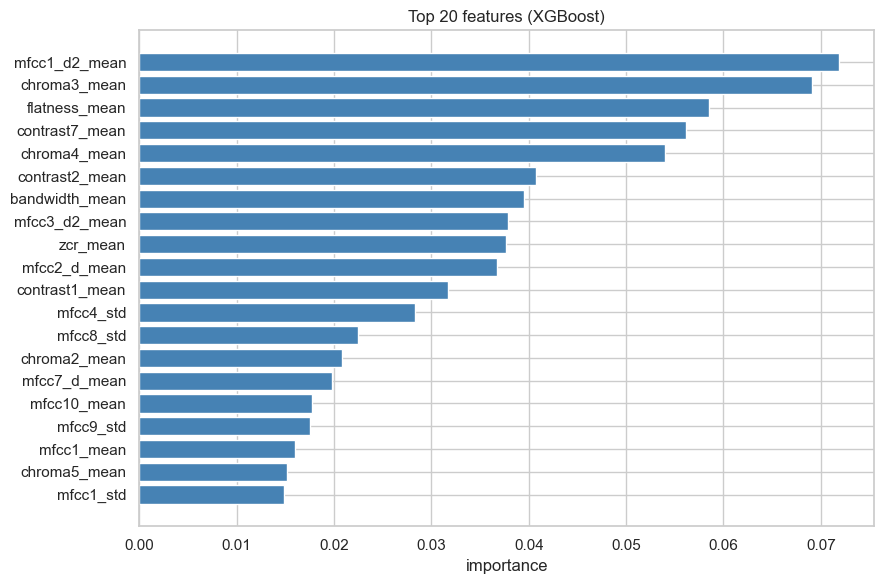

,feature,importance
3,mfcc1_d2_mean,0.071865
54,chroma3_mean,0.069042
76,flatness_mean,0.058561
70,contrast7_mean,0.056200
55,chroma4_mean,0.054032
65,contrast2_mean,0.040751
75,bandwidth_mean,0.039561
11,mfcc3_d2_mean,0.037822
71,zcr_mean,0.037692
6,mfcc2_d_mean,0.036703


In [11]:
xgb_pipe = models['XGBoost']
xgb_pipe.fit(X, y)  # fit no dataset completo só para importance
importances = xgb_pipe.named_steps['clf'].feature_importances_
imp_df = (pd.DataFrame({'feature': FEATURE_COLS, 'importance': importances})
          .sort_values('importance', ascending=False).head(20))

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp_df['feature'][::-1], imp_df['importance'][::-1], color='steelblue')
ax.set_title('Top 20 features (XGBoost)')
ax.set_xlabel('importance')
plt.tight_layout(); plt.show()
imp_df

## Resumo

1. **Métricas a nível de gravação** podem ser otimistas porque pacientes COPD têm muitas gravações.
2. **A nível de paciente é a métrica honesta** — esperamos queda especialmente em URTI (14 pacientes só).
3. Com COPD em ~62% dos pacientes, um classificador trivial "sempre COPD" já acerta 62% — qualquer modelo precisa superar essa baseline.

**Próximos passos sugeridos:**
- Hyperparameter tuning (GridSearchCV com `cv=StratifiedGroupKFold`)
- Abordagem por **ciclo respiratório** (notebook 04)
- CNN sobre mel-spectrogramas (notebook 05)